In [1]:
import pandas as pd

df = pd.read_csv("amazon.csv")

In [2]:
df.shape

(1465, 16)

In [3]:
task2_cols = [
    'discount_percentage',
    'rating',
    'discounted_price',
    'rating_count',
    'category'
]

df[task2_cols].head()

,discount_percentage,rating,discounted_price,rating_count,category
0,64%,4.2,₹399,"24,269",Computers&Accessories|Accessories&Peripherals|...
1,43%,4.0,₹199,"43,994",Computers&Accessories|Accessories&Peripherals|...
2,90%,3.9,₹199,"7,928",Computers&Accessories|Accessories&Peripherals|...
3,53%,4.2,₹329,"94,363",Computers&Accessories|Accessories&Peripherals|...
4,61%,4.2,₹154,"16,905",Computers&Accessories|Accessories&Peripherals|...


In [4]:
df[task2_cols].info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   discount_percentage  1465 non-null   str  
 1   rating               1465 non-null   str  
 2   discounted_price     1465 non-null   str  
 3   rating_count         1463 non-null   str  
 4   category             1465 non-null   str  
dtypes: str(5)
memory usage: 57.4 KB


In [5]:
print("Number of categories:", df['category'].nunique())

df['category'].value_counts().head(20)

Number of categories: 211


category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                        233
Electronics|WearableTechnology|SmartWatches                                                               76
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                      68
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                             63
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                              52
Electronics|HomeTheater,TV&Video|Accessories|RemoteControls                                               49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders                                  27
Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables                                            24
Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice                            24
Home&Kitch

In [6]:
task2 = df[[
    'discount_percentage',
    'rating',
    'discounted_price',
    'rating_count',
    'category'
]].copy()

In [7]:
task2['discount_percentage'] = (
    task2['discount_percentage']
    .str.replace('%', '', regex=False)
    .astype(float)
)

task2['discounted_price'] = (
    task2['discounted_price']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

task2['rating'] = pd.to_numeric(
    task2['rating'],
    errors='coerce'
)

task2['rating_count'] = (
    task2['rating_count']
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [8]:
task2['main_category'] = (
    task2['category']
    .str.split('|')
    .str[0]
)

In [9]:
task2[['discount_percentage',
       'rating',
       'discounted_price',
       'rating_count',
       'category',
       'main_category']].head()

,discount_percentage,rating,discounted_price,rating_count,category,main_category
0,64.0,4.2,399.0,24269.0,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories
1,43.0,4.0,199.0,43994.0,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories
2,90.0,3.9,199.0,7928.0,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories
3,53.0,4.2,329.0,94363.0,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories
4,61.0,4.2,154.0,16905.0,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories


In [10]:
print("Main categories:", task2['main_category'].nunique())

task2['main_category'].value_counts()

Main categories: 9


main_category
Electronics              526
Computers&Accessories    453
Home&Kitchen             448
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64

In [11]:
task2 = task2.dropna(
    subset=[
        'discount_percentage',
        'rating',
        'discounted_price',
        'rating_count',
        'main_category'
    ]
).copy()

In [12]:
task2.isnull().sum()

discount_percentage    0
rating                 0
discounted_price       0
rating_count           0
category               0
main_category          0
dtype: int64

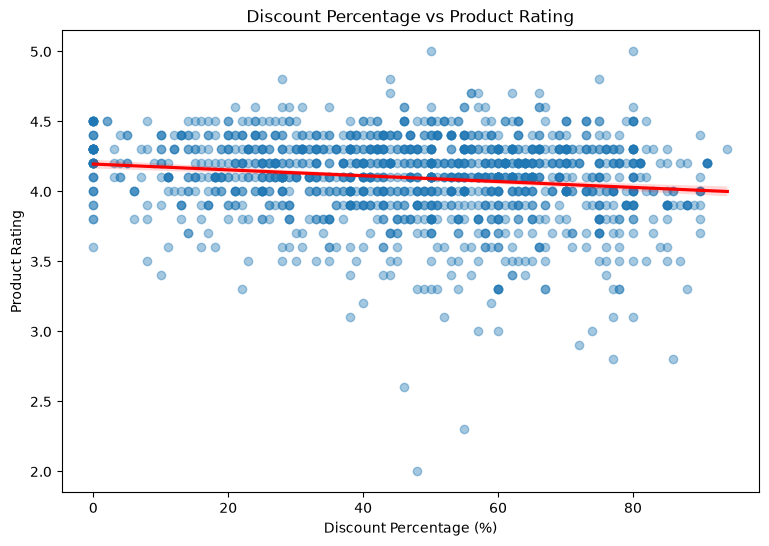

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

sns.regplot(
    data=task2,
    x='discount_percentage',
    y='rating',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Discount Percentage vs Product Rating')
plt.xlabel('Discount Percentage (%)')
plt.ylabel('Product Rating')
plt.show()

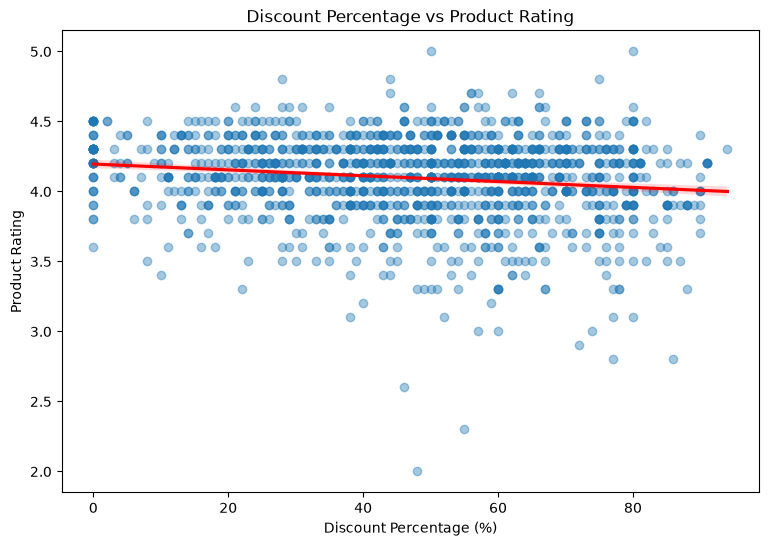

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

sns.regplot(
    data=task2,
    x='discount_percentage',
    y='rating',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Discount Percentage vs Product Rating')
plt.xlabel('Discount Percentage (%)')
plt.ylabel('Product Rating')
plt.show()

In [15]:
import pandas as pd

bins = [-1, 20, 40, 60, 80, 100]

labels = [
    '0–20%',
    '21–40%',
    '41–60%',
    '61–80%',
    '81–100%'
]

task2['discount_range'] = pd.cut(
    task2['discount_percentage'],
    bins=bins,
    labels=labels
)

rating_by_discount = task2.groupby(
    'discount_range',
    observed=False
).agg(
    product_count=('rating', 'count'),
    average_rating=('rating', 'mean'),
    median_rating=('rating', 'median')
).round(3)

rating_by_discount

,product_count,average_rating,median_rating
discount_range,,,
0–20%,179,4.173,4.2
21–40%,338,4.126,4.1
41–60%,508,4.079,4.1
61–80%,378,4.076,4.1
81–100%,59,3.976,4.0


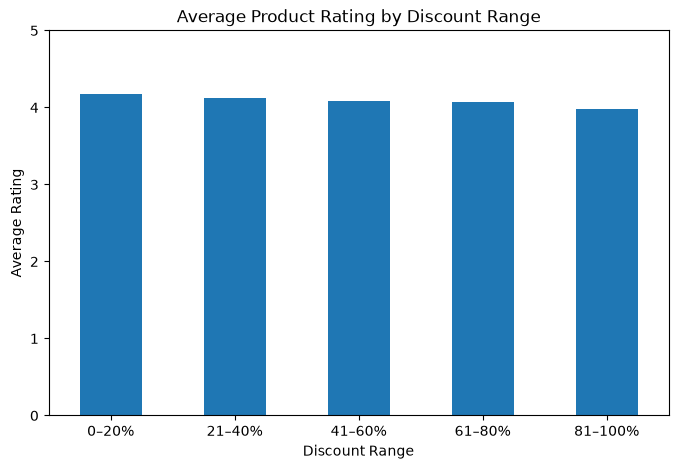

In [16]:
rating_by_discount['average_rating'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Product Rating by Discount Range')
plt.xlabel('Discount Range')
plt.ylabel('Average Rating')
plt.xticks(rotation=0)
plt.ylim(0, 5)
plt.show()

In [17]:
from scipy.stats import pearsonr, spearmanr

discount = task2['discount_percentage']
rating = task2['rating']

pearson_r, pearson_p = pearsonr(discount, rating)
spearman_r, spearman_p = spearmanr(discount, rating)

print("Pearson Correlation")
print("Correlation:", round(pearson_r, 4))
print("P-value:", round(pearson_p, 6))

print("\nSpearman Correlation")
print("Correlation:", round(spearman_r, 4))
print("P-value:", round(spearman_p, 6))

Pearson Correlation
Correlation: -0.1557
P-value: 0.0

Spearman Correlation
Correlation: -0.1462
P-value: 0.0


In [18]:
print(f"Pearson p-value: {pearson_p:.10e}")
print(f"Spearman p-value: {spearman_p:.10e}")

Pearson p-value: 2.1774104848e-09
Spearman p-value: 1.9623115054e-08


In [ ]:
%pip install statsmodels

import numpy as np
import statsmodels.formula.api as smf

task2['category_group'] = task2['main_category'].where(
    task2['main_category'].map(
        task2['main_category'].value_counts()
    ) >= 30,
    'Other'
)
task2['log_price'] = np.log1p(task2['discounted_price'])
task2['log_rating_count'] = np.log1p(task2['rating_count'])
model = smf.ols(
    'rating ~ discount_percentage + log_price + '
    'log_rating_count + C(category_group)',
    data=task2
).fit(cov_type='HC3')

print(model.summary())


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.120
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     22.87
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           1.44e-29
Time:                        11:23:05   Log-Likelihood:                -168.44
No. Observations:                1462   AIC:                             352.9
Df Residuals:                    1454   BIC:                             395.2
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                                          coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------

In [20]:
model_interaction = smf.ols(
    'rating ~ discount_percentage * C(category_group) + '
    'log_price + log_rating_count',
    data=task2
).fit(cov_type='HC3')

print(model_interaction.summary())

                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.126
Model:                            OLS   Adj. R-squared:                  0.119
Method:                 Least Squares   F-statistic:                     14.65
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           3.17e-27
Time:                        11:23:06   Log-Likelihood:                -163.19
No. Observations:                1462   AIC:                             350.4
Df Residuals:                    1450   BIC:                             413.8
Df Model:                          11                                         
Covariance Type:                  HC3                                         
                                                              coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------

In [ ]:

outlier_cols = ['discounted_price', 'rating_count']

mask = pd.Series(True, index=task2.index)

for col in outlier_cols:
    q1 = task2[col].quantile(0.25)
    q3 = task2[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask &= task2[col].between(lower, upper)

task2_no_extreme = task2.loc[mask].copy()

print("Original rows:", len(task2))
print("Rows after outlier removal:", len(task2_no_extreme))
print("Rows removed:", len(task2) - len(task2_no_extreme))

Original rows: 1462
Rows after outlier removal: 1120
Rows removed: 342


In [22]:
from scipy.stats import pearsonr, spearmanr

p_r, p_p = pearsonr(
    task2_no_extreme['discount_percentage'],
    task2_no_extreme['rating']
)

s_r, s_p = spearmanr(
    task2_no_extreme['discount_percentage'],
    task2_no_extreme['rating']
)

print(f"Pearson r: {p_r:.4f}, p-value: {p_p:.4e}")
print(f"Spearman rho: {s_r:.4f}, p-value: {s_p:.4e}")

Pearson r: -0.1554, p-value: 1.7158e-07
Spearman rho: -0.1482, p-value: 6.3106e-07


In [23]:
model_no_extreme = smf.ols(
    'rating ~ discount_percentage + log_price + '
    'log_rating_count + C(category_group)',
    data=task2_no_extreme
).fit(cov_type='HC3')

print(model_no_extreme.summary())

                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.124
Model:                            OLS   Adj. R-squared:                  0.119
Method:                 Least Squares   F-statistic:                     21.05
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           9.72e-27
Time:                        11:23:06   Log-Likelihood:                -197.40
No. Observations:                1120   AIC:                             410.8
Df Residuals:                    1112   BIC:                             451.0
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

In [24]:
print("FULL DATASET")
print("Coefficient:", round(model.params['discount_percentage'], 6))
print("P-value:", model.pvalues['discount_percentage'])

print("\nAFTER OUTLIER FILTERING")
print("Coefficient:",
      round(model_no_extreme.params['discount_percentage'], 6))
print("P-value:",
      model_no_extreme.pvalues['discount_percentage'])

FULL DATASET
Coefficient: -0.001287
P-value: 0.0011995166519846298

AFTER OUTLIER FILTERING
Coefficient: -0.001959
P-value: 1.531879729349277e-05
